In [1]:
import pandas as pd
import sys
sys.path.append('../src') # Allows us to import from src folder
from preprocessing import get_preprocessor
from sklearn.model_selection import train_test_split

# 1. Load Data
df = pd.read_csv('../data/raw/student_mental_health.csv')

# 2. Split X and y
X = df.drop(columns=['Mental_Health_Risk'])
y = df['Mental_Health_Risk']

# 3. Identify column types
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
cat_cols = [column for column in cat_cols if column != 'Student_ID']

# 4. Train/Test Split (Stratified!)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Fit the feature-engineering and preprocessing pipeline ON TRAIN ONLY
preprocessor = get_preprocessor(num_cols, cat_cols)
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"Train shape before: {X_train.shape}, after: {X_train_processed.shape}")
print(f"Test shape before: {X_test.shape}, after: {X_test_processed.shape}")
processed_feature_names = preprocessor.get_feature_names_out()
X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=processed_feature_names,
    index=X_train.index,
)
display(X_train_processed_df.head())
print(f"Processed feature names: {processed_feature_names}")

Train shape before: (1600, 16), after: (1600, 22)
Test shape before: (400, 16), after: (400, 22)


,num__Age,num__Year_of_Study,num__Sleep_Hours,num__Study_Hours_Per_Week,num__GPA,num__Social_Media_Hours,num__Screen_Time_Hours,num__Financial_Stress,num__Family_Support,num__Attendance_Rate,...,num__Support_Stress_Balance,ordinal__Physical_Activity,ordinal__Diet_Quality,nominal__Gender_Female,nominal__Gender_Male,nominal__Gender_Non-binary,nominal__Part_Time_Job_No,nominal__Part_Time_Job_Yes,nominal__Previous_Mental_Health_History_No,nominal__Previous_Mental_Health_History_Yes
726,-0.063471,-0.471636,-1.407010,-0.239251,0.075154,0.152640,1.102483,0.713748,0.643008,-1.262159,...,-0.064123,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1384,0.876838,-1.232340,-1.679538,-1.334412,-0.979124,0.333883,0.195167,-0.842691,0.368687,-0.474507,...,0.886581,2.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1579,-1.003780,-0.471636,0.409842,-0.517387,-1.037695,-0.300466,-0.833123,-0.305988,0.752736,0.777296,...,0.767743,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1098,0.876838,-1.232340,1.409111,-0.082800,0.895148,0.786989,1.102483,0.821088,-0.948052,-0.221334,...,-1.292116,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
582,0.406684,0.289067,0.409842,0.664691,-0.276272,-0.391088,-0.349222,0.660077,0.697872,-1.473137,...,0.015102,2.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0


Processed feature names: ['num__Age' 'num__Year_of_Study' 'num__Sleep_Hours'
 'num__Study_Hours_Per_Week' 'num__GPA' 'num__Social_Media_Hours'
 'num__Screen_Time_Hours' 'num__Financial_Stress' 'num__Family_Support'
 'num__Attendance_Rate' 'num__Sleep_Deficit' 'num__Academic_Engagement'
 'num__Support_Stress_Balance' 'ordinal__Physical_Activity'
 'ordinal__Diet_Quality' 'nominal__Gender_Female' 'nominal__Gender_Male'
 'nominal__Gender_Non-binary' 'nominal__Part_Time_Job_No'
 'nominal__Part_Time_Job_Yes' 'nominal__Previous_Mental_Health_History_No'
 'nominal__Previous_Mental_Health_History_Yes']


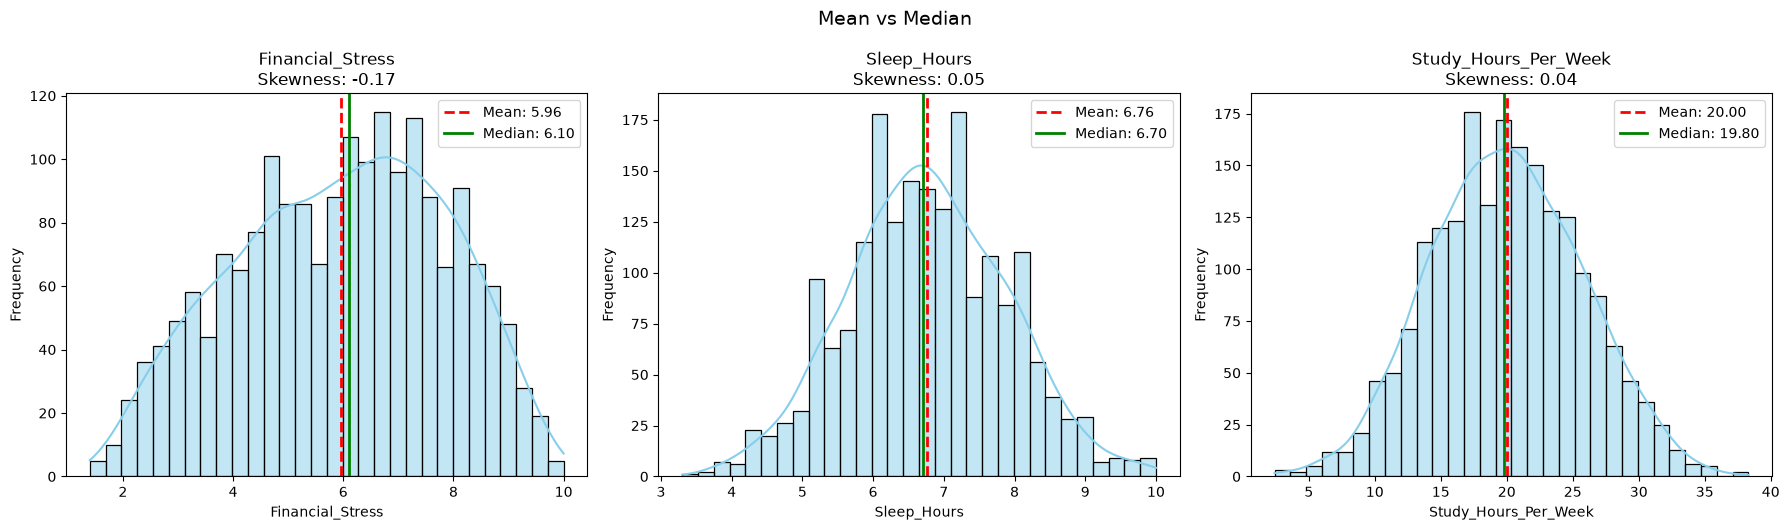

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# We'll plot the features that had missing values and visible skewness
cols_to_plot = ['Financial_Stress', 'Sleep_Hours', 'Study_Hours_Per_Week']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(cols_to_plot):
    # Calculate values
    mean_val = df[col].mean()
    median_val = df[col].median()
    skew_val = df[col].skew() # Pandas built-in skewness calculation
    
    # Plot histogram + KDE
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i], color='skyblue', bins=30)
    
    # Add vertical lines for Mean and Median
    axes[i].axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
    axes[i].axvline(median_val, color='green', linestyle='-', linewidth=2, label=f'Median: {median_val:.2f}')
    
    # Formatting
    axes[i].set_title(f'{col}\nSkewness: {skew_val:.2f}')
    axes[i].set_ylabel('Frequency')
    axes[i].legend()

plt.tight_layout()
plt.suptitle("Mean vs Median", y=1.05, fontsize=14)
plt.show()